# Rotated power conservation and strong duality of the scattered-voltage bound

Setup and global bound as in `VscatBound.ipynb`: the copper 2:1 plate (`*_patch21ka1.txt`, $ka = 1$, 2.45 GHz) in the Cholesky-whitened basis
($Z_\mathrm{mat} = Z_s 1$), with the scattered voltage $x = V_\mathrm{sca} = -Z_0 I$ as the variable.

**Rotation.** The power conservation $\operatorname{Re}[I^H P(V + V_\mathrm{sca} - Z_s I)] = 0$ with $P = p\,1$ is rotated in the complex plane, $p = e^{j\theta}$ and
$p = -j e^{j\theta}$. The quadratic part of the first constraint is then the Hermitian part of $e^{j\theta} Z_\mathrm{tot}$,
$$\operatorname{Re}(e^{j\theta} Z_\mathrm{tot}) = \cos\theta\, R - \sin\theta\, X, \qquad Z_\mathrm{tot} = R + jX .$$
It stays positive definite only on a narrow interval of $\theta$ (from the generalized eigenvalues of $(X, R)$). In the scattered-voltage space its
condition number drops strongly toward the upper end of that interval.

**Question.** Does the rotation move the dual toward strong duality, i.e. reduce
- the duality gap $D - P(x^\star)$,
- the constraint residuals at the dual current,
- the near-singularity of $A(\lambda^\star)$ (hard case),

or make the GCD results reproducible?

**Expectation.** The rotated pair spans the same constraints as $p = 1$ and $p = -j$, since $\operatorname{Re}(\overline{a} w)$ for any complex $a$ is a real
combination of the two. The dual problem is therefore the same, and so are its optimum and its GCD projectors (the library's max-violation and
min-eigenvalue projectors are complex and rotation-covariant). A rotation can only change the numerical path: the dual-feasible starting
point, the conditioning of the Newton solve, and the GCD realization. The notebook tests this.

In [1]:
import numpy as np
import scipy.sparse as sp
import time
from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters

In [2]:
matrixSet = "patch21ka1"   # "dipole" | "patch21ka1": operators loaded from *_{matrixSet}.txt (both ka = 1)

# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
wavelength = c / frequency # wavelength in m
print(f"Wavelength: {wavelength} m")

ka = 1 # electrical size of the antenna
k = 2 * np.pi / wavelength # wavenumber
a = ka / k # antenna circumradius
print(f"Antenna circumradius: {a} m")

omega = 2 * np.pi * frequency # angular frequency

conductivity_reduction_factor = 1 # factor to reduce conductivity for testing purposes
copper_conductivity = conductivity_reduction_factor*5.96e7 # S/m
copper_permittivity = 1 + 1j * copper_conductivity / (omega * epsilon_0) # copper permittivity in dimensionless units
print(f"Copper permittivity: {copper_permittivity:.2e}")

Wavelength: 0.1223655664053944 m
Antenna circumradius: 0.019475084757658086 m
Copper permittivity: 1.00e+00+4.37e+08j


In [3]:
# Calculate surface impedance
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta)
print(f"Surface impedance: {Zs} Ω")

# Load matrices from text files
Lmat = np.loadtxt(f"Lmat_{matrixSet}.txt", delimiter=',') # lossy matrix

Ndes = Lmat.shape[0] # number of design variables
print(f"Matrix set: {matrixSet}, number of design variables: {Ndes}")

Lchol = np.linalg.cholesky(Lmat).conj().T
LcholInv = np.linalg.inv(Lchol)

def Msym(M):
    return(0.5*(M.conj().T + M))

def Mchol(M):
    return(Msym(LcholInv.conj().T @ M @ LcholInv))

R0 = np.loadtxt(f"R0_{matrixSet}.txt", delimiter=',') # radiated power matrix
R0 = Mchol(R0)

X0 = np.loadtxt(f"X0_{matrixSet}.txt", delimiter=',') # reactive power matrix
X0 = Mchol(X0)

Vinc = np.loadtxt(f"V_{matrixSet}.txt", delimiter=',') # voltage excitation vector
Vinc = E0*Vinc
def Vchol(v):
    return(LcholInv.conj().T @ v)
Vinc = Vchol(Vinc)

Zmat = Zs * np.eye(Ndes) # material impedance matrix
Z0 = R0 + 1j*X0 # free-space impedance matrix
Ztot = Z0 + Zmat # total impedance matrix

def evalObjI(Ivec):
    # radiated power in the current basis
    return(0.5*np.real(Ivec.conj().T @ R0 @ Ivec))

# full plate performance
Ifull = np.linalg.solve(Ztot, Vinc) # current distribution for full plate
Pfull = evalObjI(Ifull) # objective for full plate
print(f"Objective for full plate: {Pfull:.6e} W")

Surface impedance: (0.012739130327240646+0.012739130327240646j) Ω
Matrix set: patch21ka1, number of design variables: 233
Objective for full plate: 4.114174e-02 W


## Objective in $V_\mathrm{sca}$

With $I = -W V_\mathrm{sca}$ the radiated power $\tfrac12 I^H R_0 I$ takes the dolphindes form
$-x^H A_0 x + 2\operatorname{Re}(x^H s_0) + c_0$, $x = V_\mathrm{sca}$, with
$$A_0 = -\tfrac12 W^H R_0 W,\qquad s_0 = 0,\qquad c_0 = 0 .$$
The quadratic part is identical to the $V_\mathrm{tot}$ formulation.

In [4]:
print(f"cond(Z0) = {np.linalg.cond(Z0):.3e}")
W = np.linalg.inv(Z0)   # Z0^{-1}
WH = W.conj().T

Obj = -0.5 * Msym(WH @ R0 @ W)
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0

def VtoI(Vsca):
    return(-W @ Vsca)

def evalObj(Vsca):
    return(-np.real(Vsca.conj().T @ Obj @ Vsca) + 2*np.real(Vsca.conj().T @ obj) + obj0)

Vfull = -Z0 @ Ifull # scattered voltage for full plate
print(f"Objective for full plate in Vsca: {evalObj(Vfull):.6e} W (I basis {Pfull:.6e} W)")

cond(Z0) = 1.174e+03
Objective for full plate in Vsca: 4.114174e-02 W (I basis 4.114174e-02 W)


## Power conservation in the shared projector form

For a complex diagonal projector $P = \operatorname{diag}(p)$ the constraint $\operatorname{Re}\left[I^H P (V + V_\mathrm{sca} - Z_s I)\right] = 0$
holds for any structure. With $I = -W V_\mathrm{sca}$ it reads $\operatorname{Re}\left(-x^H B x + 2x^H s\right) = 0$,
$$B = W^H P (1 + Z_s W),\qquad s = -\tfrac12 W^H P V ,$$
without a constant. Using $\operatorname{Re}(x^H B x) = \operatorname{Re}(x^H B^H x)$, $B^H = (1 + Z_s^* W^H)\, P^*\, W$, this is the shared projector form
$\operatorname{Re}\left(-x^H A_1 P' A_2 x + 2 x^H A_2^H P'^H s_1\right) = 0$ with
$$A_1 = 1 + Z_s^* W^H,\qquad A_2 = W,\qquad s_1 = -\tfrac12 V,\qquad P' = P^H = \operatorname{diag}(p^*),$$
i.e. the current-basis constraint with $U^H = A_1$ and $I = -A_2 x$ written in $V_\mathrm{sca}$.

The global real ($p = \mathbf 1$) and reactive ($p = -j\mathbf 1$) power constraints are $P' = \mathbf 1$ and $P' = j\mathbf 1$.
For $P' = \mathbf 1$, $\operatorname{Sym}(A_1 A_2) = W^H \operatorname{Re}(Z_\mathrm{tot}) W$ (using $\operatorname{Sym}W = W^H R_0 W$),
the congruent image of the $I$-basis real power constraint.

In [5]:
A1 = np.eye(Ndes) + np.conj(Zs) * WH
A2 = W
s1 = -0.5 * Vinc

qList = [1, -1j]   # real and imaginary part (real and reactive power), p = q 1
Plist = [sp.diags(np.conj(q)*np.ones(Ndes, dtype=complex)) for q in qList]   # P' = diag(p^*)

def projRes(x, Pp):
    # Re(-x^H A1 P' A2 x + 2 x^H A2^H P'^H s1)
    return(np.real(-x.conj() @ A1 @ (Pp @ (A2 @ x)) + 2*x.conj() @ (A2.conj().T @ (Pp.conj().T @ s1))))

def directRes(Vsca, p):
    # Re[I^H diag(p) (V + Vsca - Zs I)] evaluated directly
    I = VtoI(Vsca)
    return(np.real(np.sum(p*np.conj(I)*(Vinc + Vsca - Zs*I))))

print("power conservation residuals at full plate:",
      [f"{projRes(Vfull, Pp):.2e} (direct {directRes(Vfull, q*np.ones(Ndes)):.2e})" for Pp, q in zip(Plist, qList)])

# check: shared projector form equals the direct constraint for a random projector at a random point
pRand = np.random.randn(Ndes) + 1j*np.random.randn(Ndes)
xRand = np.random.randn(Ndes) + 1j*np.random.randn(Ndes)
print(f"random p, random x: shared form {projRes(xRand, sp.diags(np.conj(pRand))):.6e}, direct {directRes(xRand, pRand):.6e}")

power conservation residuals at full plate: ['-1.39e-17 (direct -2.89e-17)', '4.44e-16 (direct -4.76e-16)']
random p, random x: shared form -7.459267e-01, direct -7.459267e-01


## Admissible rotations and the conditioning of the rotated real power

In the whitened basis $R = R_0 + \operatorname{Re}(Z_s)$ and $X = X_0 + \operatorname{Im}(Z_s)$. The rotated real power $\cos\theta R - \sin\theta X$ is positive definite for
$\theta \in (\arctan(1/g_\mathrm{min}), \arctan(1/g_\mathrm{max}))$, with $g$ the generalized eigenvalues of $(X, R)$. The sweep uses angles across that interval.

generalized eigenvalues of (X, R) in [-4.914e+05, 2.061e+03] -> Re(e^(j theta) Ztot) > 0 for theta in (-1.1659e-04, 2.7803e-02) deg


theta 0.0000e+00 deg: cond current space 2.130e+03, cond scattered-voltage space 1.171e+07
theta 6.9508e-03 deg: cond current space 2.824e+03, cond scattered-voltage space 1.931e+05
theta 1.3902e-02 deg: cond current space 4.238e+03, cond scattered-voltage space 9.735e+04
theta 2.5023e-02 deg: cond current space 2.121e+04, cond scattered-voltage space 5.428e+04
theta 2.7664e-02 deg: cond current space 4.225e+05, cond scattered-voltage space 4.912e+04


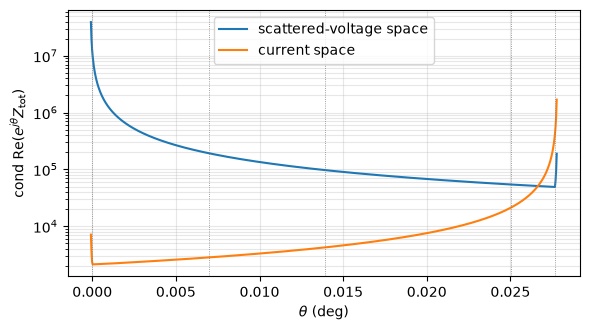

In [6]:
import scipy.linalg as sla
import copy, contextlib, io
import matplotlib.pyplot as plt
from dolphindes.cvxopt.gcd import GCDHyperparameters

Rt, Xt = (0.5*(Ztot + Ztot.conj().T)).real, (-0.5j*(Ztot - Ztot.conj().T)).real # Ztot = R + j X
g = sla.eigh(Xt, Rt, eigvals_only=True)
thLo, thHi = np.arctan(1/g.min()), np.arctan(1/g.max())
print(f"generalized eigenvalues of (X, R) in [{g.min():.3e}, {g.max():.3e}] -> Re(e^(j theta) Ztot) > 0 for theta in "
      f"({np.degrees(thLo):.4e}, {np.degrees(thHi):.4e}) deg")

def rotReal(th):
    return np.cos(th)*Rt - np.sin(th)*Xt

def condPair(th):
    H = rotReal(th)
    ev = np.linalg.eigvalsh(H); evv = np.linalg.eigvalsh(Msym(WH @ H @ W))
    return ev[-1]/ev[0], evv[-1]/evv[0]

thScan = np.linspace(thLo, thHi, 801)[1:-1]
cScan = np.array([condPair(th) for th in thScan])
thOpt = thScan[np.argmin(cScan[:, 1])]
thetas = [0.0, 0.25*thHi, 0.5*thHi, 0.9*thHi, thOpt]
for th in thetas:
    cI, cV = condPair(th)
    print(f"theta {np.degrees(th):.4e} deg: cond current space {cI:.3e}, cond scattered-voltage space {cV:.3e}")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.semilogy(np.degrees(thScan), cScan[:, 1], label='scattered-voltage space')
ax.semilogy(np.degrees(thScan), cScan[:, 0], label='current space')
for th in thetas:
    ax.axvline(np.degrees(th), c='gray', lw=0.6, ls=':')
ax.set_xlabel(r'$\theta$ (deg)'); ax.set_ylabel(r'cond Re$(e^{j\theta} Z_\mathrm{tot})$'); ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## Global bound with the rotated constraint pair

For every $\theta$ the starting multiplier on the rotated real power is $\lambda_0 = 1.05 \cdot \tfrac12 \max \operatorname{eig}(R_0, \operatorname{Re}(e^{j\theta} Z_\mathrm{tot}))$, the smallest value
that makes $A = -\tfrac12 W^H R_0 W + \lambda_0 W^H \operatorname{Re}(e^{j\theta} Z_\mathrm{tot}) W$ positive definite (with a 5 % margin).

The report gives, per $\theta$:
- the bound and the gap $D - P(x^\star)$;
- the residuals of the two power constraints, evaluated in the unrotated form $p = 1, -j$ so that all angles are comparable;
- the smallest eigenvalue of $A(\lambda^\star)$ relative to the largest;
- the change of $x^\star$ against $\theta = 0$;
- the number of dual evaluations and the time.

In [7]:
opt_params = OptimizationHyperparameters(opttol=1e-6, gradConverge=True, min_inner_iter=10, max_restart=10,
    penalty_ratio=1e-2, penalty_reduction=0.1, break_iter_period=5, verbose=0) # as in VscatBound.ipynb

def rotatedPlist(th):
    qs = [np.exp(1j*th), -1j*np.exp(1j*th)]
    return qs, [sp.diags(np.conj(q)*np.ones(Ndes, dtype=complex)) for q in qs]

# check: the rotated constraint at a random point equals Re(e^(j theta) I^H (V + Vsca - Zs I))
qs, Pr = rotatedPlist(thOpt)
print(f"rotated constraint check: shared form {projRes(xRand, Pr[0]):.6e}, direct {directRes(xRand, qs[0]*np.ones(Ndes)):.6e}")

def lambda0(th):
    return 1.05*0.5*sla.eigh(R0, rotReal(th), eigvals_only=True)[-1]

def countEvals(Q):
    count = [0]
    orig = Q.get_dual
    def counted(*a, **k):
        count[0] += 1
        return orig(*a, **k)
    Q.get_dual = counted
    return count

def dualReport(name, Q, x0=None, t=None, n=None):
    x = Q.current_xstar
    A = Msym(Q._get_total_A(Q.current_lags))
    ev = np.linalg.eigvalsh(A)
    res = [projRes(x, Pp) for Pp in Plist] # unrotated p = 1, -j
    out = dict(D=Q.current_dual, gap=Q.current_dual - evalObj(x), res=np.abs(res)/Q.current_dual, lamRatio=ev[0]/ev[-1], x=x,
               dx=np.nan if x0 is None else np.linalg.norm(x - x0)/np.linalg.norm(x0))
    print(f"{name}: D {out['D']:.9e} W, gap (D - P(x*))/D {out['gap']/out['D']:+.1e}, |c_real|/D {out['res'][0]:.1e}, |c_reactive|/D {out['res'][1]:.1e}, "
          f"min/max eig A {out['lamRatio']:.1e}, |x* - x*(0)|/|x*(0)| {out['dx']:.1e}"
          + ("" if n is None else f", {n} dual evaluations") + ("" if t is None else f", {t:.2f}s"))
    return out

glob = {}
for th in thetas:
    qs, Pr = rotatedPlist(th)
    Q = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, Pr, A2=A2, verbose=0)
    l0 = np.array([lambda0(th), 0.0])
    cnt = countEvals(Q)
    t1 = time.time()
    Q.solve_current_dual_problem(method='newton', init_lags=l0, opt_params=opt_params)
    del Q.get_dual
    glob[th] = dict(Q=Q, **dualReport(f"theta {np.degrees(th):.4e} deg (lambda0 {l0[0]:.3f})", Q,
                                      None if th == 0.0 else glob[0.0]["x"], time.time() - t1, cnt[0]))

rotated constraint check: shared form -1.649977e-02, direct -1.649977e-02


theta 0.0000e+00 deg (lambda0 0.525): D 1.847943996e+01 W, gap (D - P(x*))/D +1.3e-08, |c_real|/D 2.5e-08, |c_reactive|/D 2.4e-04, min/max eig A 4.7e-06, |x* - x*(0)|/|x*(0)| nan, 236 dual evaluations, 0.10s


theta 6.9508e-03 deg (lambda0 0.525): D 1.847943996e+01 W, gap (D - P(x*))/D +5.6e-09, |c_real|/D 1.3e-08, |c_reactive|/D 1.5e-04, min/max eig A 4.7e-06, |x* - x*(0)|/|x*(0)| 8.4e-08, 341 dual evaluations, 0.17s


theta 1.3902e-02 deg (lambda0 0.524): D 1.847943996e+01 W, gap (D - P(x*))/D +5.5e-09, |c_real|/D 2.3e-09, |c_reactive|/D 1.8e-04, min/max eig A 4.7e-06, |x* - x*(0)|/|x*(0)| 4.0e-07, 364 dual evaluations, 0.18s


theta 2.5023e-02 deg (lambda0 0.575): D 1.847943996e+01 W, gap (D - P(x*))/D +2.6e-08, |c_real|/D 3.6e-08, |c_reactive|/D 1.3e-04, min/max eig A 4.7e-06, |x* - x*(0)|/|x*(0)| 1.0e-07, 341 dual evaluations, 0.16s


theta 2.7664e-02 deg (lambda0 0.883): D 1.847943996e+01 W, gap (D - P(x*))/D -3.5e-09, |c_real|/D 1.3e-08, |c_reactive|/D 3.7e-04, min/max eig A 4.7e-06, |x* - x*(0)|/|x*(0)| 1.3e-07, 340 dual evaluations, 0.17s


## GCD with the rotated constraint pair

GCD (20 iterations, two projectors per iteration) from the global solution, for $\theta = 0$ and for the angle with the best scattered-voltage
conditioning, each with three seeds. The random coefficients of `Pstruct` are seeded; the eigensolver start vector is not, so the
realizations differ. The report gives, per run:
- the bound, the gap and the residuals of the two power constraints;
- the smallest eigenvalue of $A(\lambda^\star)$;
- the spread over the realizations, of the bound and of the dual current $x^\star$.

In [8]:
Ngcd = 20

def localViolation(Vsca):
    # pointwise w_i = I_i^* (V + Vsca - Zs I)_i, zero for any physical structure (as in VscatBound.ipynb)
    I = VtoI(Vsca)
    return(np.conj(I)*(Vinc + Vsca - Zs*I))
gcd_params = GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd, max_gcd_iter_num=Ngcd, gcd_iter_period=Ngcd + 1, opt_params=opt_params)

gcdRuns = {}
for th in [0.0, thOpt]:
    gcdRuns[th] = []
    for seed in [0, 1, 2]:
        np.random.seed(seed)
        qs, Pr = rotatedPlist(th)
        Q = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, Pr, A2=A2, verbose=0)
        Q.solve_current_dual_problem(method='newton', init_lags=np.array([lambda0(th), 0.0]), opt_params=opt_params)
        t1 = time.time()
        with contextlib.redirect_stdout(io.StringIO()):
            Q.run_gcd(gcd_params)
        r = dualReport(f"GCD {Ngcd}, theta {np.degrees(th):.4e} deg, seed {seed}", Q, None, time.time() - t1)
        r["wNorm"] = np.linalg.norm(localViolation(r["x"]))
        r["Q"] = Q
        gcdRuns[th].append(r)
    Ds = np.array([r["D"] for r in gcdRuns[th]]); xsr = [r["x"] for r in gcdRuns[th]]
    print(f"  theta {np.degrees(th):.4e} deg: bound spread {(Ds.max() - Ds.min())/Ds.mean():.1e}, dual current spread "
          f"{max(np.linalg.norm(a - b)/np.linalg.norm(b) for i, a in enumerate(xsr) for b in xsr[i + 1:]):.2e}, "
          f"||local violation|| {np.median([r['wNorm'] for r in gcdRuns[th]]):.3e}")
xa, xb = gcdRuns[0.0][0]["x"], gcdRuns[thOpt][0]["x"]
print(f"theta 0 vs theta opt (seed 0): bound difference {abs(gcdRuns[0.0][0]['D'] - gcdRuns[thOpt][0]['D'])/gcdRuns[0.0][0]['D']:.1e}, "
      f"|x*_0 - x*_opt| / |x*_0| {np.linalg.norm(xa - xb)/np.linalg.norm(xa):.2e}")

GCD 20, theta 0.0000e+00 deg, seed 0: D 1.777937297e+01 W, gap (D - P(x*))/D +4.1e-05, |c_real|/D 2.4e-03, |c_reactive|/D 3.4e+02, min/max eig A 3.5e-12, |x* - x*(0)|/|x*(0)| nan, 24.77s


GCD 20, theta 0.0000e+00 deg, seed 1: D 1.778034358e+01 W, gap (D - P(x*))/D +1.7e-05, |c_real|/D 2.4e-03, |c_reactive|/D 3.4e+02, min/max eig A 4.2e-12, |x* - x*(0)|/|x*(0)| nan, 27.02s


GCD 20, theta 0.0000e+00 deg, seed 2: D 1.777940701e+01 W, gap (D - P(x*))/D +1.8e-05, |c_real|/D 2.4e-03, |c_reactive|/D 3.5e+02, min/max eig A 2.9e-11, |x* - x*(0)|/|x*(0)| nan, 26.86s
  theta 0.0000e+00 deg: bound spread 5.5e-05, dual current spread 5.50e-01, ||local violation|| 2.911e+03


GCD 20, theta 2.7664e-02 deg, seed 0: D 1.778008744e+01 W, gap (D - P(x*))/D +1.5e-05, |c_real|/D 2.3e-03, |c_reactive|/D 3.4e+02, min/max eig A 2.9e-11, |x* - x*(0)|/|x*(0)| nan, 27.07s


GCD 20, theta 2.7664e-02 deg, seed 1: D 1.778002252e+01 W, gap (D - P(x*))/D -8.2e-06, |c_real|/D 3.0e-03, |c_reactive|/D 3.5e+02, min/max eig A 4.1e-12, |x* - x*(0)|/|x*(0)| nan, 27.95s


GCD 20, theta 2.7664e-02 deg, seed 2: D 1.777882989e+01 W, gap (D - P(x*))/D +3.9e-05, |c_real|/D 2.6e-03, |c_reactive|/D 3.4e+02, min/max eig A 2.9e-11, |x* - x*(0)|/|x*(0)| nan, 26.84s
  theta 2.7664e-02 deg: bound spread 7.1e-05, dual current spread 5.02e-01, ||local violation|| 2.858e+03
theta 0 vs theta opt (seed 0): bound difference 4.0e-05, |x*_0 - x*_opt| / |x*_0| 2.32e-01


## Rotated real-power ellipsoids and the projection onto both global constraints

In `main.tex` (Section "Distance to the Dissipated Power Constraint" and "Completed square of a constraint") the global real power
$2\operatorname{Re}(x^H s) - x^H A x = 0$, $A = W^H \operatorname{Re}(Z_\mathrm{tot}) W \succ 0$, is written as the ellipsoid $(x - o)^H A (x - o) = \gamma$, $o = A^{-1}s$, $\gamma = s^H o$, with the signed
relative distance $d(x) = (\|C(x - o)\| - \sqrt\gamma)/\sqrt\gamma$. The reactive power is indefinite and has no such form.

**Rotated ellipsoids.** For every admissible $\theta$ the rotated real power $\operatorname{Re}(e^{j\theta} Z_\mathrm{tot}) \succ 0$ is again an ellipsoid on which every structure lies.
- It mixes in the reactive power with weight $\tan\theta \leq 4.9\times10^{-4}$.
- It is much better conditioned in the scattered voltage.

Two different angles span both global constraints, so the intersection of two ellipsoids is exactly the set where the real and the reactive
power balance hold. This is the projection that `main.tex` leaves open ("the reactive constraint ... needs a separate treatment").

**Test.**
1. **Distances.** $d_\theta(x)$ of the global and the GCD dual currents ($\theta = 0$, three realizations) from the rotated ellipsoids.
2. **Projection onto both global constraints.** $\min_x (x - x_0)^H M (x - x_0)$ subject to both global constraints. This is a two-constraint QCQP with a positive
   definite objective, solved by its dual (strongly dual for two constraints). Three metrics are compared:
   - Euclidean, $M = 1$;
   - the real-power ellipsoid, $M = A_0$;
   - the best-conditioned rotated ellipsoid, $M = A_{\theta_\mathrm{opt}}$.

   The report gives the move, the residuals, the scattered power, the Lagrangian distance $J = (x_p - x^\star)^H L^\star (x_p - x^\star)$ of the GCD run, and the
   spread of the projected currents over the realizations.

In [9]:
def ellipsoid(th):
    # rotated real power 2 Re(x^H s) - x^H A x = 0 as (x - o)^H A (x - o) = gamma
    Q = glob[th]["Q"]
    A, s = Msym(Q.precomputed_As[0]), Q.Fs[:, 0]
    o = np.linalg.solve(A, s)
    return dict(A=A, s=s, o=o, gamma=np.real(s.conj() @ o), lamMin=np.linalg.eigvalsh(A)[0])

ells = {th: ellipsoid(th) for th in thetas}
for th, e in ells.items():
    ev = np.linalg.eigvalsh(e["A"])
    print(f"theta {np.degrees(th):.4e} deg: A > 0 {ev[0] > 0}, cond A {ev[-1]/ev[0]:.2e}, gamma {e['gamma']:.4f} W")

def relDist(x, e):
    return (np.sqrt(np.real((x - e["o"]).conj() @ e["A"] @ (x - e["o"]))) - np.sqrt(e["gamma"]))/np.sqrt(e["gamma"])

gamma0 = ells[0.0]["gamma"]
def reactiveRes(x):
    return projRes(x, Plist[1])/gamma0

currents = {"global x*": glob[0.0]["x"], **{f"GCD x*, seed {i}": r["x"] for i, r in enumerate(gcdRuns[0.0])}}
print("\nsigned relative distance d_theta(x) from the rotated real-power ellipsoids (theta in deg); c_im/gamma_0 is the reactive residual")
for name, x in currents.items():
    print(f"  {name:16s}: " + ", ".join(f"{np.degrees(th):.2e}: {relDist(x, e):+.2e}" for th, e in ells.items())
          + f"; c_im/gamma_0 {reactiveRes(x):+.2e}")

theta 0.0000e+00 deg: A > 0 True, cond A 1.17e+07, gamma 11.4940 W
theta 6.9508e-03 deg: A > 0 True, cond A 1.93e+05, gamma 10.9392 W
theta 1.3902e-02 deg: A > 0 True, cond A 9.74e+04, gamma 11.5397 W
theta 2.5023e-02 deg: A > 0 True, cond A 5.43e+04, gamma 13.6399 W
theta 2.7664e-02 deg: A > 0 True, cond A 4.91e+04, gamma 14.8795 W

signed relative distance d_theta(x) from the rotated real-power ellipsoids (theta in deg); c_im/gamma_0 is the reactive residual
  global x*       : 0.00e+00: -2.05e-08, 6.95e-03: +2.88e-09, 1.39e-02: +2.58e-08, 2.50e-02: +5.31e-08, 2.77e-02: +5.55e-08; c_im/gamma_0 +3.82e-04
  GCD x*, seed 0  : 0.00e+00: -1.83e-03, 6.95e-03: -3.62e-02, 1.39e-02: -6.79e-02, 2.50e-02: -1.04e-01, 2.77e-02: -1.05e-01; c_im/gamma_0 -5.28e+02
  GCD x*, seed 1  : 0.00e+00: -1.82e-03, 6.95e-03: -3.58e-02, 1.39e-02: -6.71e-02, 2.50e-02: -1.03e-01, 2.77e-02: -1.04e-01; c_im/gamma_0 -5.21e+02
  GCD x*, seed 2  : 0.00e+00: -1.86e-03, 6.95e-03: -3.67e-02, 1.39e-02: -6.89e-02, 2.50e-02

In [10]:
def projectBoth(x0, M):
    # argmin (x - x0)^H M (x - x0) s.t. the global real and reactive power (two-constraint QCQP, solved by its dual)
    M = Msym(M)/np.linalg.norm(M, 2)
    Qp = DenseSharedProjQCQP(M, M @ x0, -np.real(x0.conj() @ M @ x0), A1, s1, Plist, A2=A2, verbose=0)
    Qp.solve_current_dual_problem(method='newton', init_lags=np.zeros(2), opt_params=opt_params)
    xp = Qp.current_xstar
    dist = np.real((xp - x0).conj() @ M @ (xp - x0))
    return xp, dict(gap=(-Qp.current_dual - dist)/max(dist, 1e-300), lamRatio=(lambda ev: ev[0]/ev[-1])(np.linalg.eigvalsh(Msym(Qp._get_total_A(Qp.current_lags)))))

metrics = {"Euclidean": np.eye(Ndes, dtype=complex), "real-power ellipsoid A_0": ells[0.0]["A"],
           f"rotated ellipsoid A(theta {np.degrees(thOpt):.4f} deg)": ells[thOpt]["A"]}
proj = {}
for mname, M in metrics.items():
    proj[mname] = []
    for i, r in enumerate(gcdRuns[0.0]):
        x0, Q = r["x"], r["Q"]
        xp, info = projectBoth(x0, M)
        e = xp - x0
        Lstar = Msym(Q._get_total_A(Q.current_lags))
        out = dict(xp=xp, move=np.linalg.norm(e)/np.linalg.norm(x0), dReal=relDist(xp, ells[0.0]), cIm=reactiveRes(xp),
                   P=evalObj(xp)/Q.current_dual, J=np.real(e.conj() @ Lstar @ e)/Q.current_dual, **info)
        proj[mname].append(out)
        print(f"{mname:36s} seed {i}: |x_p - x*|/|x*| {out['move']:.2e}, d_0 {out['dReal']:+.1e}, c_im/gamma_0 {out['cIm']:+.1e}, "
              f"P(x_p)/D {out['P']:.4f}, J/D {out['J']:.2e}, projection gap {out['gap']:+.1e}, min/max eig {out['lamRatio']:.1e}")
    xps = [p["xp"] for p in proj[mname]]
    print(f"  {mname}: spread of the projected currents over the realizations "
          f"{max(np.linalg.norm(a - b)/np.linalg.norm(b) for k, a in enumerate(xps) for b in xps[k + 1:]):.2e} "
          f"(dual currents {max(np.linalg.norm(a['x'] - b['x'])/np.linalg.norm(b['x']) for k, a in enumerate(gcdRuns[0.0]) for b in gcdRuns[0.0][k + 1:]):.2e})")

Euclidean                            seed 0: |x_p - x*|/|x*| 8.85e-02, d_0 +8.5e-08, c_im/gamma_0 +9.0e-05, P(x_p)/D 0.9599, J/D 5.01e-02, projection gap -3.4e-07, min/max eig 5.8e-02


Euclidean                            seed 1: |x_p - x*|/|x*| 8.55e-02, d_0 -2.9e-08, c_im/gamma_0 -3.7e-05, P(x_p)/D 0.9614, J/D 4.86e-02, projection gap +1.5e-07, min/max eig 5.9e-02


Euclidean                            seed 2: |x_p - x*|/|x*| 9.21e-02, d_0 +3.5e-09, c_im/gamma_0 +3.5e-06, P(x_p)/D 0.9581, J/D 5.18e-02, projection gap -1.3e-08, min/max eig 5.7e-02
  Euclidean: spread of the projected currents over the realizations 5.62e-01 (dual currents 5.50e-01)


real-power ellipsoid A_0             seed 0: |x_p - x*|/|x*| 1.28e+00, d_0 -1.0e-08, c_im/gamma_0 -1.0e-02, P(x_p)/D 1.0019, J/D 3.97e-03, projection gap +2.7e-05, min/max eig 2.1e-08


real-power ellipsoid A_0             seed 1: |x_p - x*|/|x*| 1.23e+00, d_0 +1.9e-08, c_im/gamma_0 -2.5e-05, P(x_p)/D 1.0019, J/D 3.71e-03, projection gap -6.6e-08, min/max eig 2.2e-08


real-power ellipsoid A_0             seed 2: |x_p - x*|/|x*| 1.34e+00, d_0 +2.7e-08, c_im/gamma_0 -5.3e-03, P(x_p)/D 1.0019, J/D 4.28e-03, projection gap +1.4e-05, min/max eig 1.9e-08
  real-power ellipsoid A_0: spread of the projected currents over the realizations 5.99e-01 (dual currents 5.50e-01)


rotated ellipsoid A(theta 0.0277 deg) seed 0: |x_p - x*|/|x*| 3.36e-01, d_0 +1.1e-08, c_im/gamma_0 +3.8e-06, P(x_p)/D 0.9914, J/D 2.30e-02, projection gap -4.8e-08, min/max eig 1.6e-05


rotated ellipsoid A(theta 0.0277 deg) seed 1: |x_p - x*|/|x*| 3.27e-01, d_0 +3.8e-09, c_im/gamma_0 -1.9e-04, P(x_p)/D 0.9918, J/D 2.25e-02, projection gap +7.6e-07, min/max eig 1.6e-05


rotated ellipsoid A(theta 0.0277 deg) seed 2: |x_p - x*|/|x*| 3.47e-01, d_0 -1.4e-09, c_im/gamma_0 -1.3e-04, P(x_p)/D 0.9910, J/D 2.37e-02, projection gap +4.9e-07, min/max eig 1.6e-05
  rotated ellipsoid A(theta 0.0277 deg): spread of the projected currents over the realizations 5.65e-01 (dual currents 5.50e-01)


## Inference from the projected currents

Pointwise inference as in `VscatBound.ipynb`, applied to the raw GCD dual currents and to their projections onto both global constraints (three
metrics, three realizations):
- **current fit** $\rho_i = \operatorname{clip}(\operatorname{Re}(\overline{b_i} I_i)/|b_i|^2, 0, 1)$, $b = (V + x)/Z_s$;
- **voltage fit** $\min_{\rho \in [0,1]^N} \|Z_s x + Z_0 \operatorname{diag}(V + x)\rho\|$ (bounded least squares).

Each density is evaluated by the scattered power of the realized structure, $(Z_s + \operatorname{diag}(\rho) Z_0) I = \operatorname{diag}(\rho) V$, relaxed and as the best
binary structure over the thresholds $0.05, \dots, 0.95$. The complex density $Z_s I_i/(V + x)_i$ shows how close the current is to a structure.

In [11]:
from scipy.optimize import lsq_linear

def fitDensity(Vsca):
    b = (Vinc + Vsca)/Zs
    I = VtoI(Vsca)
    return np.clip(np.real(np.conj(b)*I)/np.abs(b)**2, 0, 1)

def fitDensityVoltage(Vsca):
    Vtot = Vinc + Vsca
    M = Z0 * Vtot[None, :]
    r = -Zs * Vsca
    return lsq_linear(np.vstack([M.real, M.imag]), np.concatenate([r.real, r.imag]), bounds=(0, 1), method='bvls', tol=1e-12).x

def realizedObj(rho):
    S = np.diag(rho.astype(complex))
    return evalObjI(np.linalg.solve(Zs*np.eye(Ndes) + S @ Z0, S @ Vinc))

thsBin = np.linspace(0.05, 0.95, 19)
def bestBinary(rho):
    P = [realizedObj((rho > t).astype(float)) for t in thsBin]
    return max(P)

def inferReport(x, D):
    rhoC = Zs*VtoI(x)/(Vinc + x)
    out = {"|complex density| max": np.abs(rhoC).max()}
    for name, fit in [("current fit", fitDensity), ("voltage fit", fitDensityVoltage)]:
        rho = fit(x)
        out[name] = (realizedObj(rho)/D, bestBinary(rho)/D)
    return out

rows = []
for i, r in enumerate(gcdRuns[0.0]):
    cases = {"raw GCD x*": r["x"], **{f"projected, {m}": proj[m][i]["xp"] for m in proj}}
    for name, x in cases.items():
        res = inferReport(x, r["D"])
        rows.append((i, name, res))
        print(f"seed {i}, {name:46s}: max|complex density| {res['|complex density| max']:.1e}; "
              + "; ".join(f"{k}: relaxed P/D {v[0]:.4f}, best binary {v[1]:.4f}" for k, v in res.items() if k != "|complex density| max"), flush=True)

seed 0, raw GCD x*                                    : max|complex density| 8.0e-03; current fit: relaxed P/D 0.0000, best binary 0.0000; voltage fit: relaxed P/D 0.0000, best binary 0.0000


seed 0, projected, Euclidean                          : max|complex density| 6.5e-03; current fit: relaxed P/D 0.0000, best binary 0.0000; voltage fit: relaxed P/D 0.0000, best binary 0.0000


seed 0, projected, real-power ellipsoid A_0           : max|complex density| 2.7e-03; current fit: relaxed P/D 0.0000, best binary 0.0000; voltage fit: relaxed P/D 0.0000, best binary 0.0000


seed 0, projected, rotated ellipsoid A(theta 0.0277 deg): max|complex density| 5.0e-03; current fit: relaxed P/D 0.0000, best binary 0.0000; voltage fit: relaxed P/D 0.0000, best binary 0.0000


seed 1, raw GCD x*                                    : max|complex density| 1.3e-02; current fit: relaxed P/D 0.0000, best binary 0.0000; voltage fit: relaxed P/D 0.0000, best binary 0.0000


...

seed 1, projected, rotated ellipsoid A(theta 0.0277 deg): max|complex density| 7.1e-03; current fit: relaxed P/D 0.0000, best binary 0.0000; voltage fit: relaxed P/D 0.0000, best binary 0.0000


seed 2, raw GCD x*                                    : max|complex density| 2.6e-02; current fit: relaxed P/D 0.0000, best binary 0.0000; voltage fit: relaxed P/D 0.0000, best binary 0.0000


seed 2, projected, Euclidean                          : max|complex density| 7.1e-03; current fit: relaxed P/D 0.0001, best binary 0.0000; voltage fit: relaxed P/D 0.0000, best binary 0.0000


seed 2, projected, real-power ellipsoid A_0           : max|complex density| 6.2e-03; current fit: relaxed P/D 0.0000, best binary 0.0000; voltage fit: relaxed P/D 0.0000, best binary 0.0000


seed 2, projected, rotated ellipsoid A(theta 0.0277 deg): max|complex density| 9.8e-03; current fit: relaxed P/D 0.0001, best binary 0.0000; voltage fit: relaxed P/D 0.0000, best binary 0.0000


## Conclusions

These are the numbers of the last run. GCD is not exactly reproducible; earlier runs agree within the stated spreads.

**Admissible rotations.** In the whitened basis $\operatorname{Re}(e^{j\theta} Z_\mathrm{tot}) \succ 0$ only for $\theta \in (-1.2\times10^{-4}°, 0.0278°)$. The generalized eigenvalues of $(X, R)$
span $[-4.9\times10^5, 2.1\times10^3]$. Over this interval the scattered-voltage condition number falls from $1.2\times10^7$ to $4.9\times10^4$, while the current-space one
rises from $2.1\times10^3$ to $4.2\times10^5$.

**Global bound: unchanged.** The bound is 18.47943996 W at every angle (10 digits). The dual current differs from $\theta = 0$ by $\leq 4\times10^{-7}$; the gap is $\leq 3\times10^{-8}$, the
real-power residual $\leq 4\times10^{-8}\,D$ and the reactive one $\leq 4\times10^{-4}\,D$. The min/max eigenvalue of $A(\lambda^\star)$ is $4.7\times10^{-6}$ at every angle. Only the starting
multiplier (0.52–0.88) and the number of dual evaluations (236 at $\theta = 0$, about 340 rotated) change.

**GCD (20 iterations, three realizations): unchanged.**

| | $\theta = 0$ | $\theta = 0.0277°$ |
|---|---|---|
| bound | 17.7794–17.7803 W | 17.7788–17.7801 W |
| min/max eig of $A(\lambda^\star)$ | $3.5\times10^{-12}$–$2.9\times10^{-11}$ | $4\times10^{-12}$–$2.9\times10^{-11}$ |
| reactive residual | $340$–$350\,D$ | $340$–$350\,D$ |
| dual current spread over realizations | 55 % | 50 % |

The dual currents at the two angles (same seed) differ by 23 %, less than two realizations at one angle do.

**Why.** The rotated pair spans the same constraint functions as $p = 1, -j$, and the dual only rotates its multipliers. The Lagrangian, bound and
dual current are invariant, and the GCD projectors are rotation-covariant.

**Rotated ellipsoids as a distance measure.**
- **All valid.** Every $A_\theta \succ 0$ is a valid ellipsoid ($\gamma_\theta$ from 11.5 W to 14.9 W).
- **They see the reactive violation.** The global dual current lies on all of them ($|d_\theta| \leq 6\times10^{-8}$). The GCD currents are $1.8\times10^{-3}$ inside the
  real-power ellipsoid but up to 0.107 inside the rotated ones, with a reactive residual of $c_\mathrm{im}/\gamma_0 = -520 \ldots -535$. The rotated distance carries
  $\tan\theta \cdot c_\mathrm{im}$, which $d_0$ cannot see.
- **Two are enough.** Two angles span both global constraints.

**Projection onto both global constraints.** This is a two-constraint QCQP, solved exactly by its dual (gap $\leq 3\times10^{-5}$, residuals $\leq 10^{-2}\,\gamma_0$).

| metric | move | $J/D$ | $P(x_p)/D$ | min/max eig of the projection dual |
|---|---|---|---|---|
| Euclidean | 8.6–9.2 % | 4.9–5.2 % | 0.958–0.961 | 0.06 |
| $A_0$ | 123–134 % | **0.37–0.43 %** | 1.002 | $2\times10^{-8}$ |
| $A_{0.0277°}$ | 33–35 % | 2.3–2.4 % | 0.991–0.992 | $1.6\times10^{-5}$ |

The projected currents differ between GCD realizations by 56–60 %, the same as the dual currents (55 %). The projection does not remove the
near-kernel randomness.

**Inference from the projected currents: no gain.** For every realization and metric, the current and voltage fits give realized structures with
$P/D \leq 10^{-4}$, relaxed and binary. The complex density stays at $|\rho| \leq 2.6\times10^{-2}$, i.e. the currents are locally far from any structure. The global
constraints, which is all the projection enforces, do not change that.

**Summary.** The rotation does not change any dual optimum. It does give a positive definite measure of the reactive violation ($d_\theta$) and a
better-conditioned metric for the exact projection onto both global constraints. Its use for scraping is tested in `scrapingBothEllipsoids*.ipynb`.